In [2]:


# ============================================
# InfraGuard AI
# Version: 0.1
# Environment Initialization
# ============================================

import os
import sys
import platform

import torch
import torchvision
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path

print("=" * 50)
print("       INFRAGUARD AI - INITIALIZATION")
print("=" * 50)

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)

# GPU configuration
if torch.cuda.is_available():

    device = torch.device("cuda")

    print("\nGPU Available:", True)
    print("GPU Name:", torch.cuda.get_device_name(0))

    gpu_memory = (
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3)
    )

    print(f"GPU Memory: {gpu_memory:.2f} GB")

else:
    device = torch.device("cpu")
    print("\nGPU Available: False")

print("\nSelected Device:", device)
print("=" * 50)


       INFRAGUARD AI - INITIALIZATION
Python: 3.13.16
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
NumPy: 2.1.3
OpenCV: 4.14.0

GPU Available: True
GPU Name: Tesla T4
GPU Memory: 14.56 GB

Selected Device: cuda


In [3]:

from pathlib import Path

PROJECT_ROOT = Path("/kaggle/working/InfraGuard-AI")

folders = [
    "configs",
    "data",
    "src/datasets",
    "src/models",
    "src/losses",
    "src/training",
    "src/evaluation",
    "src/utils",
    "notebooks",
    "checkpoints",
    "results/figures",
    "results/predictions",
    "app",
    "tests",
    "research_paper"
]

for folder in folders:
    (PROJECT_ROOT / folder).mkdir(
        parents=True,
        exist_ok=True
    )

os.chdir(PROJECT_ROOT)

print("Project directory created!")
print("\nProject structure:\n")

for path in sorted(PROJECT_ROOT.rglob("*")):
    if path.is_dir():
        print("📁", path.relative_to(PROJECT_ROOT))


Project directory created!

Project structure:

📁 app
📁 checkpoints
📁 configs
📁 data
📁 notebooks
📁 research_paper
📁 results
📁 results/figures
📁 results/predictions
📁 src
📁 src/datasets
📁 src/evaluation
📁 src/losses
📁 src/models
📁 src/training
📁 src/utils
📁 tests


In [4]:

# Test GPU tensor operations

x = torch.randn(
    2, 3, 256, 256,
    device=device
)

print("Tensor shape:", x.shape)
print("Device:", x.device)

# Test Torchvision ROI Align
features = torch.randn(
    1, 4, 32, 32,
    device=device
)

rois = torch.tensor(
    [[0, 2, 2, 20, 20]],
    dtype=torch.float32,
    device=device
)

output = torchvision.ops.roi_align(
    features,
    rois,
    output_size=(7, 7)
)

print("ROI Align output:", output.shape)

print("\nEnvironment test completed!")


Tensor shape: torch.Size([2, 3, 256, 256])
Device: cuda:0
ROI Align output: torch.Size([1, 4, 7, 7])

Environment test completed!


In [6]:

!pip -q install "datasets>=3.0.0"


In [7]:

# ============================================
# InfraGuard AI - CiF Dataset Connection
# ============================================

from datasets import load_dataset

DATASET_ID = "ibm-research/cif-dataset"

# Load only training configuration
# Streaming prevents downloading the entire dataset.

train_stream = load_dataset(
    DATASET_ID,
    name="train_tiled",
    split="train",
    streaming=True
)

print("Dataset connection successful!")
print("Dataset type:", type(train_stream))


README.md:   0%|          | 0.00/7.25k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/188 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/78 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/76 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/80 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/24 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/24 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/80 [00:00<?, ?it/s]

Dataset connection successful!
Dataset type: <class 'datasets.iterable_dataset.IterableDataset'>


In [8]:

# Get one sample for inspection

sample = next(iter(train_stream))

print("Image ID:", sample["image_id"])
print("File name:", sample["file_name"])

print("Image dimensions:",
      sample["width"], "x", sample["height"])

print("\nAvailable fields:")
print(sample.keys())

print("\nAnnotation fields:")
print(sample["objects"].keys())

print("\nDefect instances:",
      len(sample["objects"]["category_id"]))

print("\nDetected categories:",
      sample["objects"]["category_id"])


Image ID: 10000001
File name: DJI_20221118111015_0027_SUPR_0_0.JPG
Image dimensions: 1024 x 1024

Available fields:
dict_keys(['image_id', 'image', 'file_name', 'width', 'height', 'source_collection', 'site', 'structure', 'component_id', 'section', 'side', 'material', 'tile_row', 'tile_col', 'file_name_original', 'width_original', 'height_original', 'parent_image_id', 'source_parent_image_id', 'objects'])

Annotation fields:
dict_keys(['id', 'category_id', 'bbox', 'area', 'iscrowd', 'segmentation'])

Defect instances: 1

Detected categories: [2]


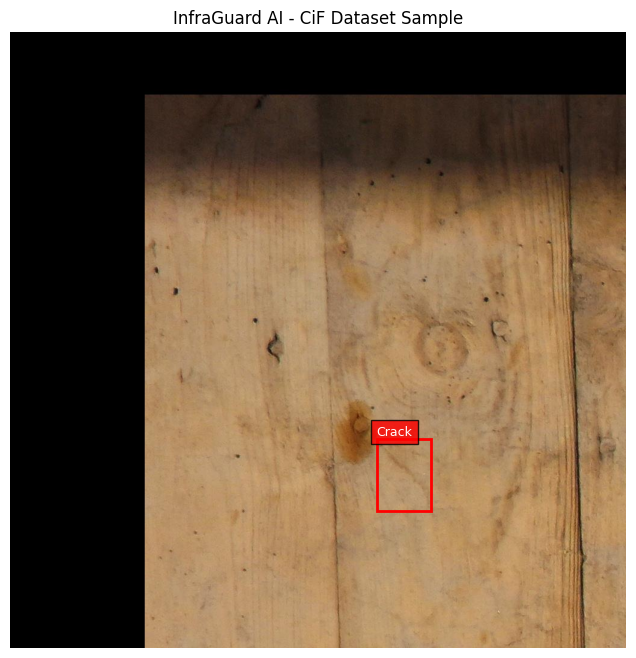

In [9]:

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

CATEGORY_NAMES = {
    1: "Algae",
    2: "Crack",
    3: "Net-Crack",
    4: "Crack with Precipitation",
    5: "Rust",
    6: "Spalling"
}

image = sample["image"].convert("RGB")
objects = sample["objects"]

fig, ax = plt.subplots(figsize=(12, 8))

ax.imshow(image)

for bbox, category_id in zip(
    objects["bbox"],
    objects["category_id"]
):
    x, y, w, h = bbox

    rect = Rectangle(
        (x, y),
        w,
        h,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rect)

    label = CATEGORY_NAMES[int(category_id)]

    ax.text(
        x,
        max(0, y - 5),
        label,
        color="white",
        fontsize=9,
        bbox=dict(
            facecolor="red",
            alpha=0.8
        )
    )

ax.set_title("InfraGuard AI - CiF Dataset Sample")
ax.axis("off")

plt.show()


In [11]:

# Dataset integrity checks

assert sample["image"] is not None
assert sample["width"] > 0
assert sample["height"] > 0

obj = sample["objects"]

assert len(obj["bbox"]) == len(obj["category_id"])
assert len(obj["segmentation"]) == len(obj["category_id"])

valid_categories = all(
    int(c) in CATEGORY_NAMES
    for c in obj["category_id"]
)

assert valid_categories

print("All basic dataset checks passed!")
print("Image:", sample["image"].size)
print("Annotations:", len(obj["category_id"]))
print("Categories:", CATEGORY_NAMES)


All basic dataset checks passed!
Image: (1024, 1024)
Annotations: 1
Categories: {1: 'Algae', 2: 'Crack', 3: 'Net-Crack', 4: 'Crack with Precipitation', 5: 'Rust', 6: 'Spalling'}
